# ML-06 — Signal Audit: Do the Flags Hold?

This skeleton is yours to fill. Work the sections **in order** — each one has a one-line hint. Simple words, honest numbers.

> Working with an AI assistant? Tell it to read `skills/README.md` first and load the one skill this assignment names on its card.

## 1. Distributions

*Look before deciding: distributions of your key fields. Note the heavy tails.*

,n,median,mean,p90,p99,max,skew
impressions_prev_30d,30000.0,210.00,1783.08,4065.00,26293.93,218786.00,11.73
impr_d61_90,30000.0,308.00,1988.23,4868.20,26283.15,258505.00,13.01
impr_momentum_prior,30000.0,-0.27,-0.30,0.69,2.95,8.21,0.44
word_count (measured only),22301.0,2877.00,3107.76,5327.00,7292.00,9546.00,0.94
content_age_days,30000.0,236.00,256.17,463.00,537.00,564.00,0.49
days_since_last_update,30000.0,20.00,46.10,104.00,106.00,373.00,1.16
avg_position (0 dropped),28795.0,11.40,17.03,37.50,70.50,245.00,2.01


top 1% of pages hold 27% of all prev_30d impressions, mean 1,783 vs median 210
days_since_last_update: 68% of pages under 30 days, and 68% of all pages sit on just two values (20 and 104 days). could be batch updates rather than real edits, I cant tell from this file


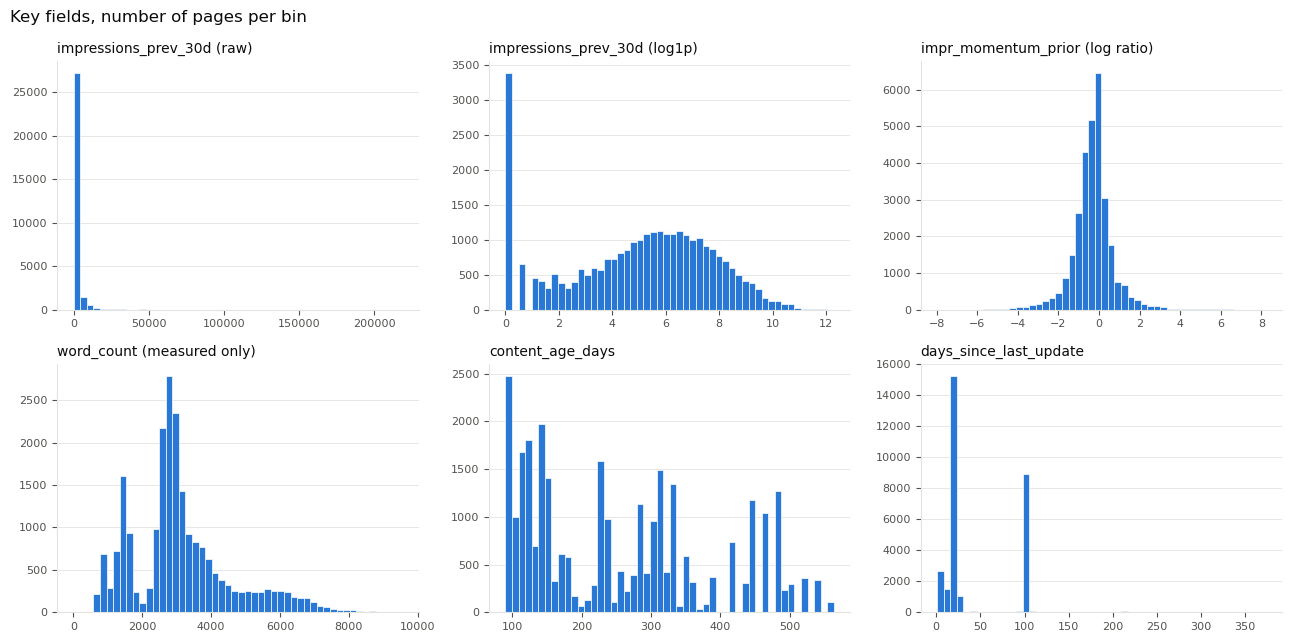

In [1]:
"""Looking before deciding. The fields that matter for my lane: the traffic windows before day -30, the momentum going into it, page length and age, plus days_since_last_update and avg_position for the flag test in section 3.
Two gotchas from the data skill applied here: word_count blanks are dropped (not 0) for the look, and avg_position = 0 means no data, not rank zero, so those rows are dropped too."""

import sys
sys.path.insert(0, "../scripts")
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lane_features as lf

raw = lf.load_raw()
df = lf.build_features(raw)
Y = "is_declining_label"
BASE = df[Y].mean()
FIG_DIR = Path("../figures")
FIG_DIR.mkdir(exist_ok=True)
INK, MUTED, GRID, BLUE = "#0b0b0b", "#52514e", "#e4e3df", "#2a78d6"

series = {
    "impressions_prev_30d": df["impressions_prev_30d"],
    "impr_d61_90": df["impr_d61_90"],
    "impr_momentum_prior": df["impr_momentum_prior"],
    "word_count (measured only)": raw["word_count"].dropna(),
    "content_age_days": df["content_age_days"],
    "days_since_last_update": df["days_since_last_update"],
    "avg_position (0 dropped)": df.loc[df["avg_position"] > 0, "avg_position"],
}
dist = pd.DataFrame({name: {"n": len(s), "median": s.median(), "mean": s.mean(), "p90": s.quantile(0.9),
                            "p99": s.quantile(0.99), "max": s.max(), "skew": s.skew()} for name, s in series.items()}).T
display(dist.round(2))

imp = df["impressions_prev_30d"].sort_values(ascending=False)
top1_share = imp.head(len(imp) // 100).sum() / imp.sum()
print(f"top 1% of pages hold {top1_share:.0%} of all prev_30d impressions, mean {imp.mean():,.0f} vs median {imp.median():,.0f}")
dsu_top = df["days_since_last_update"].value_counts().head(2)
print(f"days_since_last_update: {(df['days_since_last_update'] < 30).mean():.0%} of pages under 30 days, and {dsu_top.sum() / len(df):.0%} of all pages sit on just two values "
      f"({dsu_top.index[0]} and {dsu_top.index[1]} days). could be batch updates rather than real edits, I cant tell from this file")

fig, axes = plt.subplots(2, 3, figsize=(13, 6.5))
panels = [
    ("impressions_prev_30d (raw)", df["impressions_prev_30d"]),
    ("impressions_prev_30d (log1p)", np.log1p(df["impressions_prev_30d"])),
    ("impr_momentum_prior (log ratio)", df["impr_momentum_prior"]),
    ("word_count (measured only)", raw["word_count"].dropna()),
    ("content_age_days", df["content_age_days"]),
    ("days_since_last_update", df["days_since_last_update"]),
]
for ax, (title, s) in zip(axes.ravel(), panels):
    ax.hist(s, bins=50, color=BLUE, edgecolor="white", linewidth=0.5)
    ax.set_title(title, fontsize=10, color=INK, loc="left")
    ax.tick_params(colors=MUTED, labelsize=8)
    ax.grid(axis="y", color=GRID, linewidth=0.6)
    ax.set_axisbelow(True)
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)
    for side in ["left", "bottom"]:
        ax.spines[side].set_color(GRID)
fig.suptitle("Key fields, number of pages per bin", x=0.01, ha="left", fontsize=12, color=INK)
fig.tight_layout()
fig.savefig(FIG_DIR / "w04_distributions.png", dpi=120)
plt.show()

## 2. Signal test #1 / #2 / #3 (verdict each)

*Three safe signals, each with a mini-test and a verdict: CONFIRMED / OPPOSITE / MIXED / FALSE.*

rows per half: {'A': 18621, 'B': 11379} | pooled base rate: 0.542

#1 claim: older pages are more likely to decline


,rate,n,rate_A,n_A,rate_B,n_B,below_floor
age_tier,,,,,,,
31-90,0.669,492,0.733,296,0.571,196,False
91-180,0.626,11780,0.618,6975,0.636,4805,False
181-365,0.515,11368,0.473,7904,0.610,3464,False
365+,0.426,6360,0.440,3446,0.410,2914,False


clients with 365+ pages: 9 | clients with 50+ old and 50+ young pages: 2, old minus young inside them: -0.21, -0.26
VERDICT #1: OPPOSITE. the oldest pages (365+) decline 43% vs 63% for 91-180 day pages, and its the same direction in both halves (A 44% vs 62%, B 41% vs 64%) and inside the 2 clients I can check. only a few clients have really old pages, so its directional, but nothing here supports "older = more decline". in practice: age alone is not a reason to put a page in the refresh queue, younger pages are the ones still settling.

#2 claim: thin pages (<1000 words) are more likely to decline


,rate,n,rate_A,n_A,rate_B,n_B,below_floor
word_count_tier,,,,,,,
<1000,0.207,973,0.205,971,1.000,2,True
1000-2000,0.556,3780,0.257,1278,0.708,2502,False
2000-3500,0.588,11263,0.613,5415,0.566,5848,False
3500+,0.597,6285,0.617,4786,0.531,1499,False


thin pages come from 7 clients, and one client holds 94% of them
VERDICT #2: MIXED. pooled it even looks OPPOSITE (thin pages decline only 21%), but 94% of thin pages are one client and half B has 2 thin pages, under the floor. in half B shorter pages (1000-2000) actually decline more (71%) than 3500+ (53%), in half A its the other way. so length has no direction I can trust here, its client mix.

#3 claim: pages that were already losing impressions before day -30 keep losing them


,rate,n,rate_A,n_A,rate_B,n_B,below_floor
momentum_bucket,,,,,,,
q1 falling,0.640,5324,0.629,2483,0.651,2841,False
q2,0.663,5322,0.666,3059,0.661,2263,False
q3 flat,0.595,5322,0.600,3471,0.585,1851,False
q4,0.548,5321,0.539,3776,0.570,1545,False
q5 rising,0.608,5323,0.590,3510,0.644,1813,False


VERDICT #3: CONFIRMED. pages falling into day -30 (q1/q2) decline 65% vs 55% for gently rising ones (q4), and both halves agree. small twist: the sharpest risers (q5) also decline more than q4, some of that is a spike falling back. in practice: the last two months of impressions are the most useful thing an editor can look at, more than age or length.


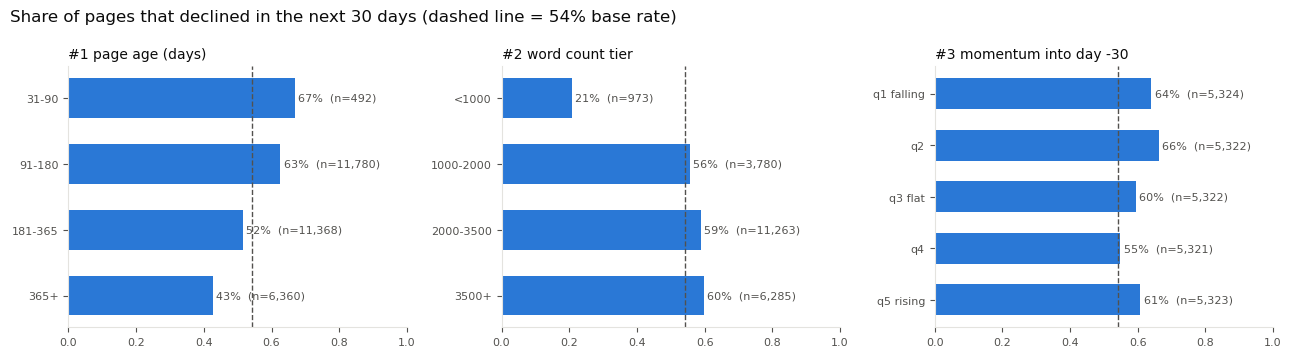

In [2]:
"""Three safe signals, all about content that people usually believe "decays". Same structure each time: the claim, a grouped table with n, and a verdict.
To check a pattern isnt one client talking, every test is rerun on a second slice: the 32 clients split into two halves (A/B, alternating by sorted id). A real signal should point the same way in both. Floor: no verdict from a bucket under 50 rows."""

FLOOR = 50
clients = sorted(df["client_id"].unique())
df["client_half"] = df["client_id"].map({c: "A" if i % 2 == 0 else "B" for i, c in enumerate(clients)})
print("rows per half:", df["client_half"].value_counts().to_dict(), "| pooled base rate:", round(BASE, 3))

def audit(frame, by, order):
    pooled = frame.groupby(by, observed=True)[Y].agg(rate="mean", n="size").reindex(order)
    halves = frame.groupby([by, "client_half"], observed=True)[Y].agg(["mean", "size"]).unstack("client_half").reindex(order)
    out = pooled.copy()
    for h in ["A", "B"]:
        out[f"rate_{h}"] = halves[("mean", h)]
        out[f"n_{h}"] = halves[("size", h)].fillna(0).astype(int)
    out["below_floor"] = (out[["n_A", "n_B"]] < FLOOR).any(axis=1)
    return out.round(3)

# signal 1: "older content declines more" (the classic content decay belief)
print("\n#1 claim: older pages are more likely to decline")
t1 = audit(df, "age_tier", ["31-90", "91-180", "181-365", "365+"])
display(t1)
# only some clients have 365+ pages, so also look inside clients that have enough old AND young pages
inside = [g.loc[g["content_age_days"] >= 365, Y].mean() - g.loc[g["content_age_days"] < 180, Y].mean()
          for _, g in df.groupby("client_id")
          if (g["content_age_days"] >= 365).sum() >= FLOOR and (g["content_age_days"] < 180).sum() >= FLOOR]
print(f"clients with 365+ pages: {df.loc[df['age_tier'] == '365+', 'client_id'].nunique()} | clients with {FLOOR}+ old and {FLOOR}+ young pages: {len(inside)}, "
      f"old minus young inside them: {', '.join(f'{d:+.2f}' for d in inside)}")
print(f"VERDICT #1: OPPOSITE. the oldest pages (365+) decline {t1.loc['365+', 'rate']:.0%} vs {t1.loc['91-180', 'rate']:.0%} for 91-180 day pages, "
      f"and its the same direction in both halves (A {t1.loc['365+', 'rate_A']:.0%} vs {t1.loc['91-180', 'rate_A']:.0%}, B {t1.loc['365+', 'rate_B']:.0%} vs {t1.loc['91-180', 'rate_B']:.0%}) "
      f"and inside the {len(inside)} clients I can check. only a few clients have really old pages, so its directional, but nothing here supports \"older = more decline\". "
      "in practice: age alone is not a reason to put a page in the refresh queue, younger pages are the ones still settling.")

# signal 2: "thin pages decline more"
print("\n#2 claim: thin pages (<1000 words) are more likely to decline")
t2 = audit(df, "word_count_tier", ["<1000", "1000-2000", "2000-3500", "3500+"])
display(t2)
thin = df[df["word_count_tier"] == "<1000"]
top_client_share = thin["client_id"].value_counts(normalize=True).iloc[0]
print(f"thin pages come from {thin['client_id'].nunique()} clients, and one client holds {top_client_share:.0%} of them")
print(f"VERDICT #2: MIXED. pooled it even looks OPPOSITE (thin pages decline only {t2.loc['<1000', 'rate']:.0%}), but {top_client_share:.0%} of thin pages are one client and half B has "
      f"{t2.loc['<1000', 'n_B']} thin pages, under the floor. in half B shorter pages (1000-2000) actually decline more ({t2.loc['1000-2000', 'rate_B']:.0%}) than 3500+ ({t2.loc['3500+', 'rate_B']:.0%}), "
      "in half A its the other way. so length has no direction I can trust here, its client mix.")

# signal 3: "pages already sliding into day -30 keep sliding"
print("\n#3 claim: pages that were already losing impressions before day -30 keep losing them")
has_prev = df[df["prev30_empty"] == 0].copy()
has_prev["momentum_bucket"] = pd.qcut(has_prev["impr_momentum_prior"], 5, labels=["q1 falling", "q2", "q3 flat", "q4", "q5 rising"])
t3 = audit(has_prev, "momentum_bucket", ["q1 falling", "q2", "q3 flat", "q4", "q5 rising"])
display(t3)
print(f"VERDICT #3: CONFIRMED. pages falling into day -30 (q1/q2) decline {t3.loc[['q1 falling', 'q2'], 'rate'].mean():.0%} vs {t3.loc['q4', 'rate']:.0%} for gently rising ones (q4), "
      "and both halves agree. small twist: the sharpest risers (q5) also decline more than q4, some of that is a spike falling back. "
      "in practice: the last two months of impressions are the most useful thing an editor can look at, more than age or length.")

# small multiples: pooled decline rate per bucket, base rate as the reference line
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharex=True)
for ax, (title, t) in zip(axes, [("#1 page age (days)", t1), ("#2 word count tier", t2), ("#3 momentum into day -30", t3)]):
    labels = [str(i) for i in t.index][::-1]
    ax.barh(labels, t["rate"].values[::-1], color=BLUE, height=0.6)
    ax.axvline(BASE, color=MUTED, linestyle="--", linewidth=1)
    for yi, (r, n) in enumerate(zip(t["rate"].values[::-1], t["n"].values[::-1])):
        ax.text(r + 0.01, yi, f"{r:.0%}  (n={int(n):,})", va="center", fontsize=8, color=MUTED)
    ax.set_title(title, fontsize=10, color=INK, loc="left")
    ax.set_xlim(0, 1)
    ax.tick_params(colors=MUTED, labelsize=8)
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)
    for side in ["left", "bottom"]:
        ax.spines[side].set_color(GRID)
fig.suptitle(f"Share of pages that declined in the next 30 days (dashed line = {BASE:.0%} base rate)", x=0.01, ha="left", fontsize=12, color=INK)
fig.tight_layout()
fig.savefig(FIG_DIR / "w04_signal_tests.png", dpi=120)
plt.show()

## 3. The flag-linked test

*Pick a signal one of FlyRank's real flags relies on. Does the data support the rule's assumption?*

In [3]:
"""The flag I picked: page_one_decay_risk from the starter baseline (lane guide): avg_position between 0 and 10 AND content_age_days >= 180. Its the assumption that old page-one pages are the ones about to slip, which is the core idea behind refreshing "aging winners".
The test: decline rate for flagged pages vs younger page-one pages vs everything else, pooled, by client half, and then INSIDE each client (so client mix cant fake it).
One caveat: avg_position is a 90 day average so it includes the label window. Thats ok for checking the flag's assumption, it would not be ok as a feature (and its not one of mine)."""

p1 = (df["avg_position"] > 0) & (df["avg_position"] <= 10)
df["flag_group"] = np.select(
    [p1 & (df["content_age_days"] >= 180), p1 & (df["content_age_days"] < 180), df["avg_position"] == 0],
    ["page1 & 180d+ (flagged)", "page1 & younger", "no position data"],
    "not page 1",
)
tf = audit(df, "flag_group", ["page1 & 180d+ (flagged)", "page1 & younger", "not page 1", "no position data"])
display(tf)

# inside each client: flagged minus younger page-one decline rate (both groups >= 30 rows, the cross-cut floor)
within = []
for cid, g in df.groupby("client_id"):
    a, b = g[g["flag_group"] == "page1 & 180d+ (flagged)"], g[g["flag_group"] == "page1 & younger"]
    if len(a) >= 30 and len(b) >= 30:
        within.append(a[Y].mean() - b[Y].mean())
within = pd.Series(within)
print(f"clients with >=30 rows in both groups: {len(within)} | flagged minus younger page-one: median {within.median():+.3f}, "
      f"range {within.min():+.2f} to {within.max():+.2f}, flagged higher in {(within > 0).sum()} of {len(within)}")

# the other refresh flag I wanted, stale_visible_page, cant even be tested here
stale = (df["days_since_last_update"] >= 180) & (df["impressions_90d"] >= 500)
print(f"stale_visible_page (180+ days since update and 500+ impressions): only {stale.sum()} pages -> insufficient data, no verdict")

print(f"""
VERDICT (page_one_decay_risk): FALSE. pooled, flagged pages decline {tf.loc['page1 & 180d+ (flagged)', 'rate']:.0%}, LESS than younger page-one pages ({tf.loc['page1 & younger', 'rate']:.0%}) and below the {BASE:.0%} base rate, same in both halves.
but inside clients the gap has no direction (median {within.median():+.3f}, flagged higher in {(within > 0).sum()} of {len(within)} clients), so the pooled gap is client mix, not age.
either way the data doesnt support "old page-one pages are the decay risk". side finding: pages with no position data decline only {tf.loc['no position data', 'rate']:.1%}, if someone read avg_position = 0 as "rank 0" they would get page one very wrong.""")

,rate,n,rate_A,n_A,rate_B,n_B,below_floor
flag_group,,,,,,,
page1 & 180d+ (flagged),0.518,7076,0.512,4763,0.530,2313,False
page1 & younger,0.617,5907,0.636,3820,0.583,2087,False
not page 1,0.566,15812,0.552,8907,0.584,6905,False
no position data,0.007,1205,0.004,1131,0.041,74,False


clients with >=30 rows in both groups: 10 | flagged minus younger page-one: median +0.011, range -0.11 to +0.08, flagged higher in 5 of 10
stale_visible_page (180+ days since update and 500+ impressions): only 17 pages -> insufficient data, no verdict

VERDICT (page_one_decay_risk): FALSE. pooled, flagged pages decline 52%, LESS than younger page-one pages (62%) and below the 54% base rate, same in both halves.
but inside clients the gap has no direction (median +0.011, flagged higher in 5 of 10 clients), so the pooled gap is client mix, not age.
either way the data doesnt support "old page-one pages are the decay risk". side finding: pages with no position data decline only 0.7%, if someone read avg_position = 0 as "rank 0" they would get page one very wrong.


## 4. What this means in practice

*Two or three sentences: what a content team should take from this.*

In [4]:
print("""What a content team should take from this:
1. Dont queue pages for refresh just because they are old or "thin". In this data age points the other way, length has no stable direction, and the page-one aging flag isnt supported once you compare inside clients.
2. The thing that does hold up in both client halves is recent momentum: a page that was already losing impressions in the two months before is the one most likely to keep losing them. Thats where my baseline and model should lean.
3. Every one of these is observed and directional on one 90 day snapshot of 32 clients. Its decision-support for where to look first, not proof that refreshing a page would stop the drop.""")

What a content team should take from this:
1. Dont queue pages for refresh just because they are old or "thin". In this data age points the other way, length has no stable direction, and the page-one aging flag isnt supported once you compare inside clients.
2. The thing that does hold up in both client halves is recent momentum: a page that was already losing impressions in the two months before is the one most likely to keep losing them. Thats where my baseline and model should lean.
3. Every one of these is observed and directional on one 90 day snapshot of 32 clients. Its decision-support for where to look first, not proof that refreshing a page would stop the drop.


## Self-check

Before you submit, confirm each line honestly:

- [x] Every section above is filled — markdown thinking AND the code that backs it
- [x] The notebook runs top to bottom with no errors (Runtime → Run all)
- [x] No client names, URLs, or private queries anywhere
- [x] My claims use careful words: observed, measured, directional, decision-support
- [ ] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.